# Deep-Sea Classification: Context Reliance & Depth Degradation
This notebook imports from the project's `.py` modules and runs the full pipeline on Colab's GPU.

# Analysis
Loads saved results from the training pipeline and runs all statistical
analyses: CRS–degradation correlation, baseline comparisons, robustness
checks, bootstrap confidence intervals, and CRS variance analysis.
No GPU required.

In [ ]:
# --- Environment bootstrap (Colab or local; no Google Drive) ---
import os, sys
try:
    import google.colab          # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Pull the code and the saved results/ from the PUBLIC repo — no Drive.
    if not os.path.isdir("cv-project"):
        !git clone --depth 1 https://github.com/kay-asp/cv-project.git
    %cd cv-project
    # Colab already ships torch/numpy/pandas/scipy/matplotlib; add only the extras.
    %pip install -q fathomnet grad-cam pycocotools
# Local: install from requirements.txt (see README) and launch Jupyter from the repo root.

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

In [ ]:
import os

import importlib
import pandas as pd
import config
import analysis
import extensions

# Load saved results
per_species_df = pd.read_csv(os.path.join(config.RESULTS_DIR, 'results.csv'), index_col='species')

# Reconstruct per-species dicts used by analysis functions
crs_scores   = per_species_df['shallow_crs'].dropna().to_dict()   # CRS on shallow test crops
degradation  = per_species_df['degradation'].dropna().to_dict()
shallow_acc  = per_species_df['shallow_acc'].dropna().to_dict()
uniform_crs  = per_species_df['uniform_crs'].dropna().to_dict()
gaussian_crs = per_species_df['gaussian_crs'].dropna().to_dict()

# Load cached predictions
int_preds = pd.read_csv(os.path.join(config.RESULTS_DIR, 'intervention_predictions.csv'))

all_ic = pd.read_csv(os.path.join(config.RESULTS_DIR, 'image_crs.csv'))
image_crs = {s: all_ic[all_ic['split'] == s].drop(columns='split') for s in ['shallow', 'deep']}

crs_cw = pd.read_csv(os.path.join(config.RESULTS_DIR, 'crs_correct_vs_incorrect.csv'))

# ── Species CRS from correctly classified shallow crops only ──
# Misclassified crops have higher CRS and lower shallow accuracy, so including them links CRS and
# degradation through the same errors; their true-class maps also explain a class the model did not choose.
# The all-crops columns are kept as shallow_all_* and define the qualifying set (139 species).
import attribution
crs_cols = ['shallow_crs', 'shallow_crs_median', 'shallow_crs_chance', 'shallow_crs_excess',
            'shallow_crs_pred', 'shallow_crs_pred_excess', 'shallow_n_crs']
for c in crs_cols:
    per_species_df[c.replace('shallow_', 'shallow_all_', 1)] = per_species_df[c]
shallow_ic = image_crs['shallow']
correct_crs = attribution.species_crs_table(shallow_ic[shallow_ic['correct']],
                                            per_species_df.index.tolist(), prefix='shallow_')
per_species_df[crs_cols] = correct_crs[crs_cols]

crs_scores  = per_species_df['shallow_crs'].dropna().to_dict()
# Uniform noise averages out to a flat map, so its expected CRS is the flat-map CRS (1 - coverage) on the same crops
uniform_crs = per_species_df['shallow_crs_chance'].dropna().to_dict()
# gaussian_crs comes from results.csv: all crops, unless train.ipynb cell 28 was rerun for correct crops

## Accuracy degradation at depth

/content/drive/Shareddrives/CV-Project/analysis.py:314: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(bin_col)["correct"].mean()


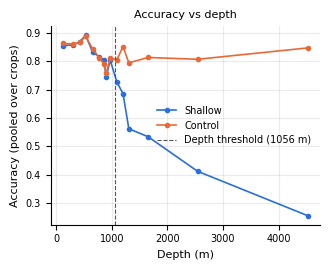

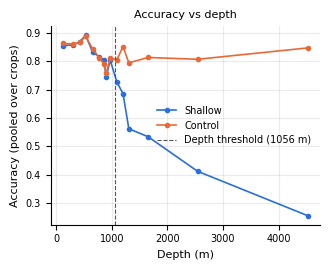

In [11]:
# degradation vs control
# Accuracy vs depth curve for shallow-trained and control models
predictions = pd.read_csv(os.path.join(config.RESULTS_DIR, 'predictions.csv'))
depth_df = pd.read_csv(config.DEPTH_PATH)

analysis.plot_accuracy_vs_depth(
    predictions, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    save_path='results/control_comparison.png')

## CRS vs degradation
Score CRS on correctly classified shallow crops only

In [12]:
# Core hypothesis test - correlation between depth degradation and context relience
# correct crops only
# TODO add back in confounded version that uses all so we have both for report

qualifying = analysis.select_qualifying_species(per_species_df, min_test_n=5, crs_col='shallow_all_crs')
rho, p_value = analysis.spearman_correlation(crs_scores, degradation, species=qualifying)
print(f'Spearman ρ = {rho:.3f}, p = {p_value:.4f}')

summary = analysis.generate_summary_table(
    crs_scores, degradation, rho, p_value, species=qualifying,
    baselines={'Uniform random': uniform_crs, 'Centre Gaussian': gaussian_crs})
summary.to_csv('results/correlation_summary.csv')
summary.round(3)



139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)
Spearman over 131 species
Spearman ρ = -0.060, p = 0.4983
Spearman over 131 species
Spearman over 131 species


,n_species,mean_crs,spearman_rho,p_value
method,,,,
Grad-CAM,131,0.421,-0.060,0.498
Uniform random,131,0.741,-0.076,0.390
Centre Gaussian,131,0.553,-0.009,0.914


### CRS vs degradation — all shallow crops (failure case)


Spearman over 139 species
All shallow crops: Spearman ρ = -0.199, p = 0.0191


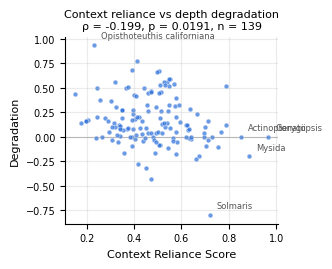

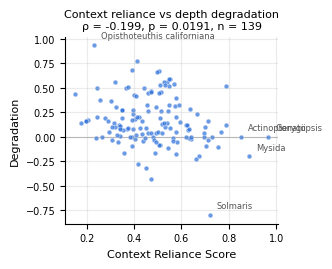

In [13]:
# CRS vs degradation over ALL shallow crops (not just correctly classified ones).
# Reported as a failure case; shallow_all_crs is the all-crops CRS set aside in the loading cell.
crs_scores_all = per_species_df['shallow_all_crs'].dropna().to_dict()
rho_all, p_all = analysis.spearman_correlation(crs_scores_all, degradation, species=qualifying)
print(f'All shallow crops: Spearman ρ = {rho_all:.3f}, p = {p_all:.4f}')

analysis.plot_crs_vs_degradation(crs_scores_all, degradation, species=qualifying, rho=rho_all,
                                 p_value=p_all, save_path='results/crs_vs_degradation_all.png')

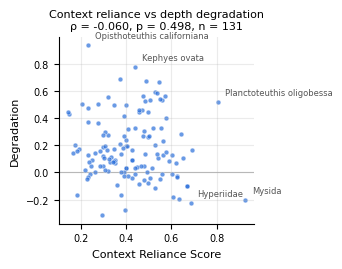

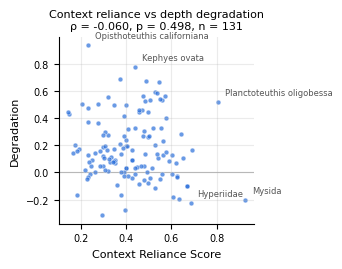

In [14]:
analysis.plot_crs_vs_degradation(crs_scores, degradation, species=qualifying, rho=rho,
                                 p_value=p_value, save_path='results/crs_vs_degradation.png')

In [15]:

from scipy.stats import spearmanr, pearsonr
import numpy as np

q = per_species_df.loc[qualifying]

# --- All-crop CRS (report section V-B and the last two rows of Table II) ---
d = q[['shallow_all_crs', 'degradation', 'shallow_acc']].dropna()
r, p = spearmanr(d['shallow_all_crs'], d['degradation'])
print(f"All-crop CRS vs degradation: rho = {r:.3f}, p = {p:.3g}, n = {len(d)}")
r, p = spearmanr(d['shallow_all_crs'], d['shallow_acc'])
print(f"All-crop CRS vs shallow accuracy: rho = {r:.3f}, p = {p:.3g}")
rk = d.rank()
resid = lambda y, x: y - np.polyval(np.polyfit(x, y, 1), x)
r, p = pearsonr(resid(rk['shallow_all_crs'], rk['shallow_acc']),
                resid(rk['degradation'], rk['shallow_acc']))
print(f"Partial (controlling for shallow accuracy): rho = {r:.3f}, p = {p:.3g}")

# --- Table II row: species with at least 3 correctly classified shallow crops ---
three = [s for s in qualifying if per_species_df.loc[s, 'shallow_n_crs'] >= 3]
r, p = analysis.spearman_correlation(crs_scores, degradation, species=three)
print(f">=3 correct shallow crops: rho = {r:.3f}, p = {p:.3g}")

# --- Table III swap rows: mean per-species accuracy for each swap condition ---
swap_preds = pd.read_csv(os.path.join(config.RESULTS_DIR, 'swap_predictions.csv'))  # loaded again in the swap section
print(swap_preds.columns.tolist())
sq = swap_preds[swap_preds['species'].isin(qualifying)]
group_cols = [c for c in sq.columns
              if sq[c].dtype == object and c not in ('species', 'pred') and 'donor' not in c]
print(sq.groupby(group_cols + ['species'])['correct'].mean()
        .groupby(group_cols).mean().round(3))

All-crop CRS vs degradation: rho = -0.199, p = 0.0191, n = 139
All-crop CRS vs shallow accuracy: rho = -0.389, p = 2.15e-06
Partial (controlling for shallow accuracy): rho = -0.068, p = 0.425
Spearman over 116 species
>=3 correct shallow crops: rho = -0.061, p = 0.514
['model', 'split', 'mode', 'bg_split', 'image_id', 'ann_id', 'species', 'pred', 'confidence', 'correct', 'donor_image_id']
model    split    mode        bg_split
control  deep     none        deep        0.665
                  swap_other  shallow     0.278
                  swap_same   deep        0.287
         shallow  none        shallow     0.636
                  swap_other  deep        0.257
                  swap_same   shallow     0.264
shallow  deep     none        deep        0.440
                  swap_other  shallow     0.185
                  swap_same   deep        0.194
         shallow  none        shallow     0.600
                  swap_other  deep        0.242
                  swap_same   shallow    

### Checking against baselines

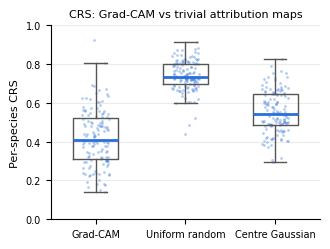

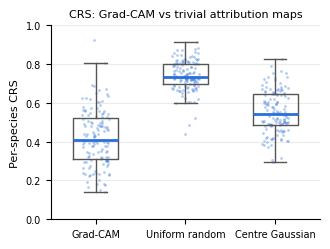

In [16]:
# Checking against baselines
# crs vs organism size (is high crs just because organism is larger in crop?)
analysis.plot_baseline_comparison(crs_scores, uniform_crs, gaussian_crs, species=qualifying,
                                  save_path='results/baseline_crs.png')


### CRS correct vs wrong predictions


,split,n_correct,n_incorrect,median_crs_correct,median_crs_incorrect,n_empty_correct,n_empty_incorrect,p_pooled,n_species_within,median_within_species_diff,p_within
0,shallow,10741,2778,0.3758,0.5013,0,32,0.0,101,0.0977,0.0
1,deep,6403,3952,0.4338,0.5941,0,85,0.0,100,0.1297,0.0


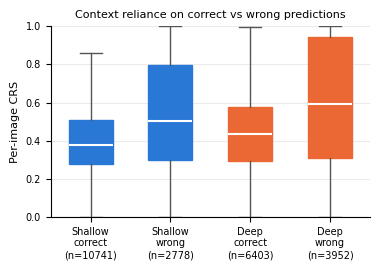

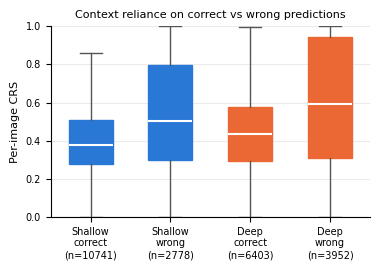

In [17]:
display(crs_cw.round(4))
extensions.plot_crs_correct_vs_incorrect(image_crs, species=qualifying,
                                         save_path='results/crs_correct_vs_wrong.png')

## CRS Robustness Check

In [18]:
# 1. Does the result depend on how many test crops a species needs?
for n in [5, 10, 20]:
    q = analysis.select_qualifying_species(per_species_df, min_test_n=n, crs_col='shallow_all_crs')
    r, p = analysis.spearman_correlation(crs_scores, degradation, species=q)
    print(f"min_test_n={n}: n_species={len(q)}, rho={r:.3f}, p={p:.3f}")

# 2. Species the model barely recognises even in shallow water can't degrade much,
#    which can hide a relationship. Re-run on species it learned reasonably well.
learned = [s for s in qualifying if shallow_acc[s] >= 0.3]
r, p = analysis.spearman_correlation(crs_scores, degradation, species=learned)
print(f"shallow_acc >= 0.3: n_species={len(learned)}, rho={r:.3f}, p={p:.3f}")

# 3. Species CRS from few crops is noisy: resample each species' crops for a CI on ρ
boot_rho = analysis.bootstrap_spearman(shallow_ic[shallow_ic['correct']], degradation, species=qualifying)

# 3b. Species are the unit of analysis: resample species (keeping each species' CRS and
#     degradation together) for a CI on ρ, the same unit the intervention CIs resample
boot_rho_species = analysis.bootstrap_spearman_species(crs_scores, degradation, species=qualifying)

# 4. Median instead of mean CRS per species (less swayed by a few extreme crops)
median_crs = per_species_df['shallow_crs_median'].dropna().to_dict()
r, p = analysis.spearman_correlation(median_crs, degradation, species=qualifying)
print(f"median CRS: n_species={len(qualifying)}, rho={r:.3f}, p={p:.3f}")

# Widest per-species CRS intervals (the least certain species), from the train notebook's bootstrap
crs_bootstrap = pd.read_csv(os.path.join(config.RESULTS_DIR, 'crs_bootstrap.csv'), index_col='species')
ci_width = (crs_bootstrap['shallow_crs_ci_high'] - crs_bootstrap['shallow_crs_ci_low']).reindex(qualifying)
display(crs_bootstrap.loc[ci_width.sort_values(ascending=False).index[:10],
                          ['shallow_crs', 'shallow_crs_ci_low', 'shallow_crs_ci_high', 'shallow_n_crs']].round(3))

# 5. Predicted-class CRS: explain the species the model chose rather than the true one (differs only
#    on wrong crops, whose true-class maps are weak and diffuse). Same test, and how close the two are
pred_crs = per_species_df['shallow_crs_pred'].dropna().to_dict()
r, p = analysis.spearman_correlation(pred_crs, degradation, species=qualifying)
print(f"predicted-class CRS: n_species={len(qualifying)}, rho={r:.3f}, p={p:.3f}")
agree = per_species_df.loc[qualifying, ['shallow_crs', 'shallow_crs_pred']].dropna()
print(f"true- vs predicted-class species CRS: Spearman ρ = "
      f"{agree['shallow_crs'].corr(agree['shallow_crs_pred'], method='spearman'):.3f}, "
      f"mean difference (pred − true) = {(agree['shallow_crs_pred'] - agree['shallow_crs']).mean():.3f}")

139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)
Spearman over 131 species
min_test_n=5: n_species=139, rho=-0.060, p=0.498
98 / 314 species qualify (>= 10 shallow and deep test crops, CRS available)
Spearman over 97 species
min_test_n=10: n_species=98, rho=-0.104, p=0.311
66 / 314 species qualify (>= 20 shallow and deep test crops, CRS available)
Spearman over 66 species
min_test_n=20: n_species=66, rho=-0.151, p=0.228
Spearman over 111 species
shallow_acc >= 0.3: n_species=111, rho=0.017, p=0.863
Spearman ρ = -0.060, 95% bootstrap CI [-0.120, -0.005] over 131 species (crops resampled within species, 2000 resamples)
Spearman ρ = -0.060, 95% bootstrap CI [-0.242, 0.129] over 131 species (species resampled, 2000 resamples)
Spearman over 131 species
median CRS: n_species=139, rho=-0.075, p=0.396


,shallow_crs,shallow_crs_ci_low,shallow_crs_ci_high,shallow_n_crs
species,,,,
Primnoidae,0.473,0.182,0.765,6
Bivalvia,0.400,0.145,0.718,6
Cerianthidae,0.551,0.289,0.805,7
Clausophyes,0.480,0.243,0.723,8
Tiburonia granrojo,0.449,0.269,0.731,5
Comatulida,0.307,0.097,0.552,10
Apolemia lanosa,0.577,0.352,0.786,7
Plexauridae,0.332,0.127,0.551,7
Decapoda,0.790,0.549,0.963,8


Spearman over 131 species
predicted-class CRS: n_species=139, rho=-0.060, p=0.498
true- vs predicted-class species CRS: Spearman ρ = 1.000, mean difference (pred − true) = 0.000


### Background shift (correct-crops CRS)

In [19]:
# Background shift with correct-crops CRS, the same CRS and species as the main test
# (131 species). train.ipynb runs the same analysis with all-crops CRS on 139 species.
spear_c, grid_c, fit_c = extensions.shift_analysis(per_species_df, species=qualifying)
display(spear_c.round(3))
print(fit_c.summary())

Shift analysis over 131 species


,spearman_rho,p_value
predictor,,
bg_colour_shift,0.115,0.192
org_colour_shift,0.238,0.006
crs,-0.060,0.498


                            OLS Regression Results                            
Dep. Variable:            degradation   R-squared:                       0.069
Model:                            OLS   Adj. R-squared:                  0.039
Method:                 Least Squares   F-statistic:                     2.329
Date:                Wed, 28 Oct 2026   Prob (F-statistic):             0.0597
Time:                        03:48:19   Log-Likelihood:                 8.6342
No. Observations:                 131   AIC:                            -7.268
Df Residuals:                     126   BIC:                             7.108
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.1785      0.020      8.820   

## Control-adjusted degradation
Some species' deep crops are harder in themselves (darker, smaller, blurrier), and
the control model, which trained on all depths, degrades on those too. Subtracting
its degradation leaves the part caused by the shallow model never seeing deep
water, which is what context reliance is meant to explain:
`degradation_adj = degradation − control_degradation`.

Spearman over 139 species
raw vs control-adjusted degradation: ρ = 0.528

Spearman over 131 species
Spearman over 111 species
Spearman over 131 species
Spearman over 111 species
Spearman over 131 species
Spearman over 111 species
Spearman ρ = -0.091, 95% bootstrap CI [-0.151, -0.045] over 131 species (crops resampled within species, 2000 resamples)


,crs,species,n,rho,p
0,CRS,qualifying,139,-0.091,0.301
1,CRS,shallow_acc >= 0.3,111,-0.086,0.371
2,excess CRS,qualifying,139,-0.042,0.638
3,excess CRS,shallow_acc >= 0.3,111,-0.026,0.786
4,predicted-class CRS,qualifying,139,-0.091,0.301
5,predicted-class CRS,shallow_acc >= 0.3,111,-0.086,0.371


Spearman over 131 species


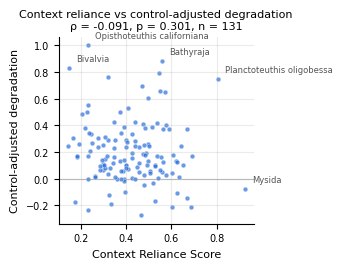

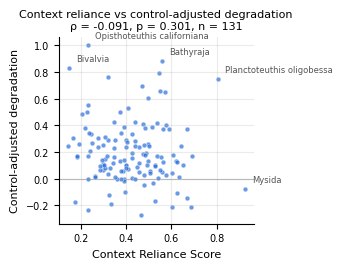

In [20]:
importlib.reload(analysis)
degradation_adj = (per_species_df['degradation'] - per_species_df['control_degradation']).dropna().to_dict()

# How much of the raw degradation ranking survives the adjustment?
r, p = analysis.spearman_correlation(degradation, degradation_adj, species=qualifying)
print(f"raw vs control-adjusted degradation: ρ = {r:.3f}\n")

adj_rows = []
for name, col in [('CRS', 'shallow_crs'), ('excess CRS', 'shallow_crs_excess'),
                  ('predicted-class CRS', 'shallow_crs_pred')]:
    scores = per_species_df[col].dropna().to_dict()
    for subset, sp in [('qualifying', qualifying), ('shallow_acc >= 0.3', learned)]:
        r, p = analysis.spearman_correlation(scores, degradation_adj, species=sp)
        adj_rows.append({'crs': name, 'species': subset, 'n': len(sp), 'rho': r, 'p': p})
adj_corr = pd.DataFrame(adj_rows)

boot_adj = analysis.bootstrap_spearman(shallow_ic[shallow_ic['correct']], degradation_adj, species=qualifying)
adj_corr.to_csv(os.path.join(config.RESULTS_DIR, 'control_adjusted_correlation.csv'), index=False)
display(adj_corr.round(3))

rho_adj_deg, p_adj_deg = analysis.spearman_correlation(crs_scores, degradation_adj, species=qualifying)
analysis.plot_crs_vs_degradation(crs_scores, degradation_adj, species=qualifying, rho=rho_adj_deg,
                                 p_value=p_adj_deg, ylabel='Control-adjusted degradation',
                                 save_path='results/crs_vs_adjusted_degradation.png')

## Crop-level model: CRS × depth
The species-level tests reduce each species to one degradation value, so a species
with 6 test crops counts as much as one with 600, and every crop's actual depth is
reduced to shallow/deep. Here every test crop is one observation:
`correct ~ depth × crs`, with crs the species' shallow CRS (standardised; never
the crop's own CRS, which the shift itself affects). Crops of one species are not
independent, which is handled two ways: a GEE with standard errors clustered by
species, and a mixed model with a random intercept per species (its own baseline
accuracy). The `depth:crs` coefficient is the test, in log-odds of a correct
prediction per SD of CRS: negative = high-CRS species lose more accuracy at depth.
Fitted with depth as shallow/deep, as continuous km relative to the threshold, and
with the control model's predictions added (`depth:crs:shallow_model`: is the
effect stronger for the shallow-trained model than for the control?).

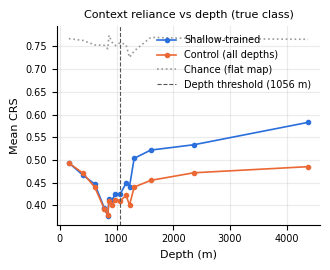

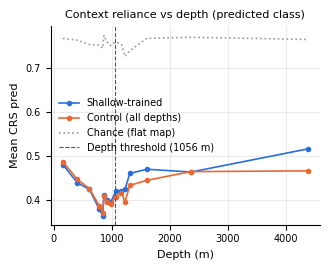

In [21]:
# Context reliance vs depth for both models, true-class and predicted-class CRS
# (the dotted chance line is the flat-map CRS: if CRS follows it, the change is mask size, not attention)
importlib.reload(analysis)
all_ic_ctrl = pd.read_csv(os.path.join(config.RESULTS_DIR, 'image_crs_control.csv'))
crs_by_model = {'shallow': all_ic, 'control': all_ic_ctrl}

for col in ['crs', 'crs_pred']:
    analysis.plot_crs_vs_depth(crs_by_model, depth_df, crs_col=col,
                               depth_threshold=config.DEPTH_SHALLOW_MAX, species=qualifying,
                               save_path=f'results/{col}_vs_depth.png')

In [22]:
# Is the CRS rise at depth a within-species change, or errors and species mix?
crs_breakdown, crs_within = analysis.crs_depth_breakdown(crs_by_model, depth_df, species=qualifying)
for m in crs_breakdown:
    print(m, 'within-species deep - shallow, correct crops: '
          'median = {:.3f}, p = {:.3g}, n = {}'.format(*crs_within[m]))
    display(crs_breakdown[m].round(3))

# Correct vs incorrect using the predicted-class map (the evidence the model actually used)
for s in ['shallow', 'deep']:
    extensions.crs_correct_vs_incorrect(
        image_crs[s].assign(crs=image_crs[s]['crs_pred']),
        species=qualifying, label=f'predicted class, {s}')

shallow within-species deep - shallow, correct crops: median = 0.001, p = 0.668, n = 102


/content/drive/Shareddrives/CV-Project/analysis.py:497: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .mean().groupby("bin_mid").mean()})
/content/drive/Shareddrives/CV-Project/analysis.py:497: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .mean().groupby("bin_mid").mean()})


,crs_all,share_wrong,crs_correct_species_weighted
bin_mid,,,
158,0.493,0.197,0.459
407,0.467,0.202,0.408
615,0.447,0.245,0.433
785,0.394,0.191,0.408
844,0.377,0.179,0.404
865,0.414,0.233,0.400
915,0.411,0.209,0.393
979,0.426,0.197,0.431
1066,0.424,0.224,0.424


control within-species deep - shallow, correct crops: median = 0.004, p = 0.565, n = 115


,crs_all,share_wrong,crs_correct_species_weighted
bin_mid,,,
159,0.493,0.193,0.441
408,0.471,0.187,0.408
616,0.440,0.219,0.415
786,0.391,0.191,0.396
844,0.379,0.190,0.412
866,0.410,0.230,0.389
916,0.401,0.200,0.394
980,0.411,0.188,0.414
1069,0.412,0.182,0.391


[predicted class, shallow] median CRS correct 0.376 vs incorrect 0.426 (pooled p = 1.08e-22); within 102 species, median diff = 0.041 (p = 2.43e-05); empty maps left out: 0 correct, 1 wrong
[predicted class, deep] median CRS correct 0.434 vs incorrect 0.453 (pooled p = 5.62e-08); within 100 species, median diff = 0.050 (p = 7.05e-05); empty maps left out: 0 correct, 5 wrong


In [23]:
# Reliability: does CRS rank species the same way on separate (deep) images?
# Same frozen model on both splits, so this tests stability, not that shallow attention causes deep attention
crs_consistency = analysis.crs_depth_consistency(all_ic, species=qualifying)

Shallow vs deep species CRS (correct crops): rho = 0.818, p = 8.8e-26, n = 102; partial on mask coverage = 0.750 (p = 1.2e-19); excess CRS rho = 0.773 (p = 1.6e-21)


In [24]:
importlib.reload(analysis)
specs = {
    'deep vs shallow': {},
    'depth (km)': {'depth_df': depth_df, 'depth_threshold': config.DEPTH_SHALLOW_MAX},
    'excess CRS': {'crs_col': 'shallow_crs_excess'},
    'shallow vs control': {'models': ('shallow', 'control')},
}
fits = []
for name, kw in specs.items():
    print(f"\n=== {name} ===")
    fits.append(analysis.crs_depth_model(predictions, per_species_df, species=qualifying, **kw)
                .assign(spec=name))
crs_depth_fits = pd.concat(fits, ignore_index=True)
crs_depth_fits.to_csv(os.path.join(config.RESULTS_DIR, 'crs_depth_model.csv'), index=False)

key_terms = crs_depth_fits[crs_depth_fits['term'].isin(['depth:crs', 'depth:crs:shallow_model'])]
display(key_terms.set_index(['spec', 'method'])[['term', 'coef', 'ci_low', 'ci_high', 'p']].round(3))


=== deep vs shallow ===
correct ~ depth * crs: 23791 crops, 131 species, depth = deep split (0/1), crs = shallow_crs (standardised)
  GEE: depth:crs = 0.356 [-0.154, 0.866], p = 0.172
  Mixed (species intercept): depth:crs = 0.195 [0.143, 0.248], p = 4.33e-13

=== depth (km) ===
correct ~ depth * crs: 23791 crops, 131 species, depth = km relative to 1056 m, crs = shallow_crs (standardised)
  GEE: depth:crs = 0.241 [0.008, 0.473], p = 0.0426
  Mixed (species intercept): depth:crs = 0.192 [0.152, 0.232], p = 3.45e-21

=== excess CRS ===
correct ~ depth * crs: 23791 crops, 131 species, depth = deep split (0/1), crs = shallow_crs_excess (standardised)
  GEE: depth:crs = 0.262 [-0.103, 0.628], p = 0.16
  Mixed (species intercept): depth:crs = 0.112 [0.051, 0.173], p = 0.000308

=== shallow vs control ===


/content/drive/Shareddrives/CV-Project/analysis.py:259: ConvergenceWarning: VB fitting did not converge
  glmm = BinomialBayesMixedGLM.from_formula(formula, {"species": "0 + C(species)"}, df).fit_vb()


correct ~ depth * crs * shallow_model: 47582 crops, 131 species, depth = deep split (0/1), crs = shallow_crs (standardised)
  GEE: depth:crs:shallow_model = 0.076 [-0.179, 0.331], p = 0.558
  Mixed (species intercept): depth:crs:shallow_model = 0.084 [0.032, 0.136], p = 0.00161


term   coef  \
spec               method                                                      
deep vs shallow    GEE                                      depth:crs  0.356   
                   Mixed (species intercept)                depth:crs  0.195   
depth (km)         GEE                                      depth:crs  0.241   
                   Mixed (species intercept)                depth:crs  0.192   
excess CRS         GEE                                      depth:crs  0.262   
                   Mixed (species intercept)                depth:crs  0.112   
shallow vs control GEE                                      depth:crs  0.280   
                   GEE                        depth:crs:shallow_model  0.076   
                   Mixed (species intercept)                depth:crs  0.139   
                   Mixed (species intercept)  depth:crs:shallow_model  0.084   

                                              ci_low  ci_high      p  
spec               method                                             
deep vs shallow    GEE                        -0.154    0.866  0.172  
                   Mixed (species intercept)   0.143    0.248  0.000  
depth (km)         GEE                         0.008    0.473  0.043  
                   Mixed (species intercept)   0.152    0.232  0.000  
excess CRS         GEE                        -0.103    0.628  0.160  
                   Mixed (species intercept)   0.051    0.173  0.000  
shallow vs control GEE                        -0.194    0.754  0.247  
                   GEE                        -0.179    0.331  0.558  
                   Mixed (species intercept)   0.099    0.180  0.000  
                   Mixed (species intercept)   0.032    0.136  0.002

## Background Intervention Results

shallow_acc  deep_acc  degradation  n_species
model   mode                                                             
shallow Original                  0.600     0.440        0.160        139
        Background greyed         0.261     0.204        0.057        139
        Background blurred        0.453     0.341        0.113        139
        Organism greyed           0.058     0.035        0.023        139
control Original                  0.636     0.665       -0.029        139
        Background greyed         0.286     0.322       -0.036        139
        Background blurred        0.493     0.519       -0.027        139
        Organism greyed           0.089     0.086        0.003        139

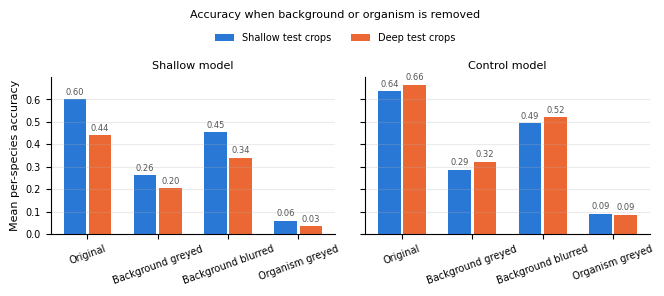

CRS vs accuracy drop (Background greyed): rho = 0.213, p = 0.0146, n = 131 species
CRS vs accuracy drop (Background blurred): rho = 0.087, p = 0.321, n = 131 species


In [25]:
importlib.reload(extensions)

int_summary = extensions.intervention_summary(int_preds, species=qualifying)
int_summary.to_csv(os.path.join(config.RESULTS_DIR, 'intervention_summary.csv'))
display(int_summary.round(3))
extensions.plot_intervention_summary(int_summary, save_path='results/intervention_accuracy.png')

# Does greying the background hurt the species Grad-CAM said rely on it?
bg_dep, bg_dep_stats = extensions.background_dependence(int_preds, crs_scores, species=qualifying)




In [26]:
boot = extensions.bootstrap_intervention(int_preds, species=qualifying)
boot.to_csv(os.path.join(config.RESULTS_DIR, 'intervention_bootstrap.csv'), index=False)
display(boot.round(3))


Bootstrap over 139 species, 2000 resamples


,model,mode,metric,estimate,ci_low,ci_high,significant
0,shallow,Background greyed,degradation,0.057,0.029,0.084,True
1,shallow,Background greyed,reduction,0.103,0.062,0.143,True
2,shallow,Background greyed,retention_gap,0.029,-0.024,0.083,False
3,control,Background greyed,degradation,-0.036,-0.066,-0.007,True
4,control,Background greyed,reduction,0.007,-0.028,0.039,False
5,control,Background greyed,retention_gap,0.035,-0.005,0.074,False
6,shallow - control,Background greyed,retention_gap,-0.006,-0.057,0.046,False
7,shallow,Background blurred,degradation,0.113,0.077,0.151,True
8,shallow,Background blurred,reduction,0.047,0.023,0.069,True
9,shallow,Background blurred,retention_gap,0.018,-0.023,0.057,False


### Background Swap

Swap decomposition over 139 species, 2000 resamples


,model,metric,estimate,ci_low,ci_high,significant
0,shallow,original_degradation,0.160,0.117,0.201,True
1,shallow,composite_degradation,0.066,0.039,0.093,True
2,shallow,background_effect,0.004,-0.006,0.014,False
3,shallow,organism_effect,0.062,0.038,0.087,True
4,shallow,compositing_cost,0.293,0.257,0.327,True
5,shallow,background_share,0.062,-0.125,0.197,False
6,control,original_degradation,-0.029,-0.067,0.008,False
7,control,composite_degradation,-0.023,-0.053,0.006,False
8,control,background_effect,-0.001,-0.012,0.010,False
9,control,organism_effect,-0.022,-0.047,0.002,False


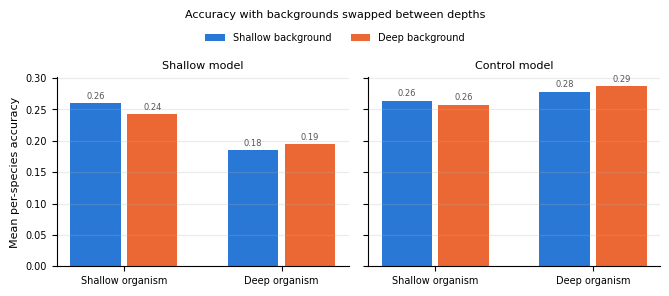

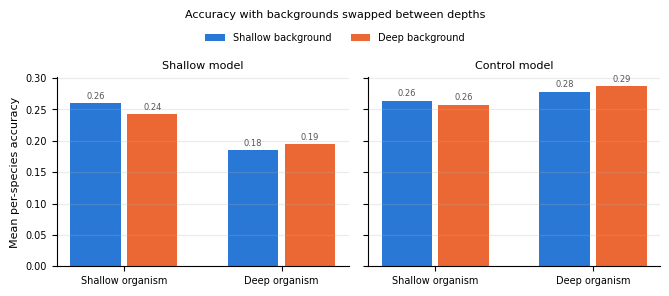

In [27]:
# Background swap: how much of the degradation follows the background vs the organism?
importlib.reload(extensions)
swap_preds = pd.read_csv(os.path.join(config.RESULTS_DIR, 'swap_predictions.csv'))

swap = extensions.swap_decomposition(swap_preds, species=qualifying)
swap.to_csv(os.path.join(config.RESULTS_DIR, 'swap_decomposition.csv'), index=False)
display(swap.round(3))

extensions.plot_swap(swap_preds, species=qualifying, save_path='results/background_swap.png')

### Within-species CRS variance vs degradation
The image-level analysis shows CRS predicts errors within species, but species-level mean CRS doesn't predict degradation. Does CRS *variance* bridge that gap? Species with inconsistent context reliance (high variance) may be more vulnerable to distribution shift than species with stable CRS.

CRS std vs degradation: rho = 0.191, p = 0.0478, n = 108 species
CRS iqr vs degradation: rho = 0.145, p = 0.135, n = 108 species
CRS mean vs degradation: rho = -0.057, p = 0.555, n = 108 species


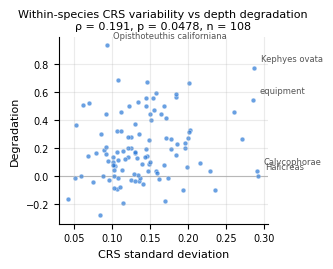

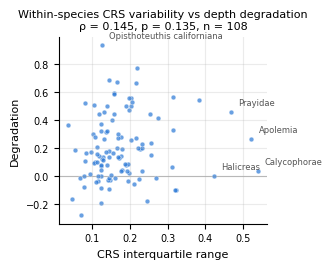

,mean,std,iqr,count,degradation
count,108.000,108.000,108.000,108.000,108.000
mean,0.422,0.141,0.177,98.981,0.203
std,0.132,0.052,0.089,149.410,0.234
min,0.143,0.043,0.037,5.000,-0.279
25%,0.323,0.106,0.123,11.000,0.030
50%,0.409,0.134,0.156,31.500,0.162
75%,0.509,0.169,0.205,107.500,0.335
max,0.806,0.292,0.538,699.000,0.933


In [28]:
importlib.reload(extensions)

# Per-species CRS std, IQR, and mean vs degradation (shallow image CRS)
var_df, var_stats = extensions.crs_variance_analysis(
    shallow_ic[shallow_ic['correct']], degradation, species=qualifying)

# Scatter plot for CRS std
rho_std, p_std, n_std = var_stats['std']
extensions.plot_crs_variance_vs_degradation(
    var_df, metric='std', rho=rho_std, p_value=p_std,
    save_path='results/crs_variance_vs_degradation.png')

# Also show IQR (more robust to outliers)
rho_iqr, p_iqr, n_iqr = var_stats['iqr']
extensions.plot_crs_variance_vs_degradation(
    var_df, metric='iqr', rho=rho_iqr, p_value=p_iqr)

display(var_df[['mean', 'std', 'iqr', 'count', 'degradation']].describe().round(3))

### CRS adjusted for mask size
CRS measures the fraction of Grad-CAM activation outside the (dilated) organism mask.
Species with smaller masks will mechanically score higher even if the model
focuses on the organism, because more area lies outside the mask.

Each crop's chance CRS is what a flat heatmap would score on its mask, i.e.
1 − organism coverage (`crs_chance`; the species mean equals `uniform_crs`).
Three ways to remove the geometric effect:
- **Excess CRS** = CRS − chance, averaged per species. 0 means no more
  context-reliant than chance; above 0 means more. It is capped at the
  coverage, so very small organisms can't score highly.
- **Partial Spearman** of CRS vs degradation, controlling for coverage.
- **OLS** `degradation ~ crs + mask_coverage` (standardised predictors).

Mask coverage vs CRS: ρ = -0.561, p = 3.09e-12, n = 131
Raw CRS vs degradation: ρ = -0.060, p = 0.498, n = 131
Excess CRS vs degradation: ρ = -0.065, p = 0.462, n = 131
CRS vs degradation, controlling for coverage: partial ρ = -0.021, p = 0.814, n = 131
OLS degradation ~ crs + coverage: crs coef = -0.016 (p = 0.529), coverage coef = 0.001 (p = 0.97)


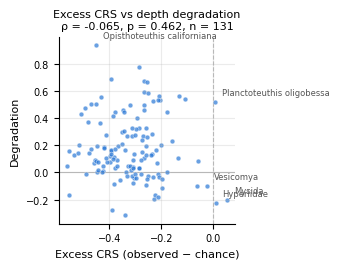

,crs,mask_coverage,crs_excess,degradation
count,131.000,131.000,131.000,131.000
mean,0.421,0.259,-0.320,0.179
std,0.144,0.078,0.119,0.236
min,0.143,0.084,-0.564,-0.314
25%,0.308,0.200,-0.398,0.012
50%,0.408,0.265,-0.313,0.133
75%,0.523,0.304,-0.255,0.321
max,0.925,0.560,0.054,0.933


In [29]:
importlib.reload(extensions)

adj_df, adj_stats, adj_fit = extensions.crs_mask_size_analysis(per_species_df, species=qualifying)

# Scatter: excess CRS vs degradation
rho_adj, p_adj, n_adj = adj_stats['excess_crs_vs_degradation']
extensions.plot_excess_crs_vs_degradation(
    adj_df, rho=rho_adj, p_value=p_adj,
    save_path='results/excess_crs_vs_degradation.png')

display(adj_df[['crs', 'mask_coverage', 'crs_excess', 'degradation']].describe().round(3))

### Is degradation driven by context reliance?
For species whose accuracy degrades at depth, is this because they relied on
background context in shallow water? If so, removing the background should
shrink the shallow-to-deep accuracy gap for degrading species more than for
non-degrading ones.

Background reliance vs degradation: ρ = -0.025, p = 0.774, n = 131
Degradation reduction vs degradation: ρ = 0.755, p = 7.71e-27, n = 139
Background reliance vs degradation: ρ = -0.040, p = 0.651, n = 131
Degradation reduction vs degradation: ρ = 0.464, p = 8.72e-09, n = 139


/content/drive/Shareddrives/CV-Project/extensions.py:844: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  orig = sub.groupby("bin_mid")[orig_col].mean()
/content/drive/Shareddrives/CV-Project/extensions.py:845: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  edit = sub.groupby("bin_mid")[edit_col].mean()
/content/drive/Shareddrives/CV-Project/extensions.py:844: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  orig = sub.groupby

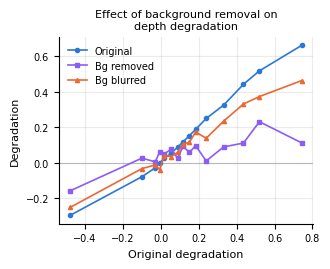

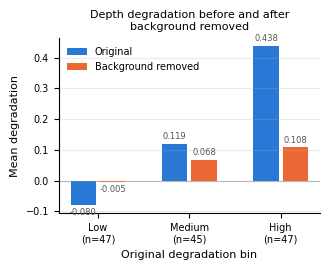

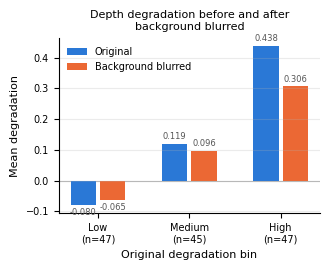


--- Control model ---
Background reliance vs degradation: ρ = -0.065, p = 0.459, n = 132
Degradation reduction vs degradation: ρ = 0.297, p = 0.00038, n = 139
Background reliance vs degradation: ρ = 0.039, p = 0.655, n = 132
Degradation reduction vs degradation: ρ = 0.088, p = 0.303, n = 139


/content/drive/Shareddrives/CV-Project/extensions.py:844: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  orig = sub.groupby("bin_mid")[orig_col].mean()
/content/drive/Shareddrives/CV-Project/extensions.py:845: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  edit = sub.groupby("bin_mid")[edit_col].mean()
/content/drive/Shareddrives/CV-Project/extensions.py:844: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  orig = sub.groupby

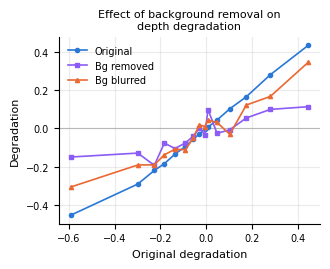

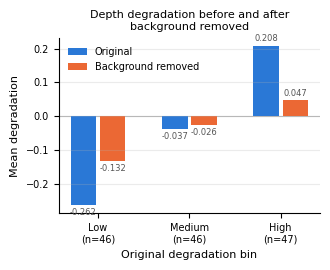

/content/drive/Shareddrives/CV-Project/analysis.py:314: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(bin_col)["correct"].mean()
/content/drive/Shareddrives/CV-Project/analysis.py:314: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(bin_col)["correct"].mean()
/content/drive/Shareddrives/CV-Project/analysis.py:314: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(bin_col)["

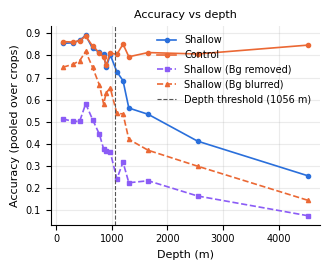

/content/drive/Shareddrives/CV-Project/analysis.py:315: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per = df.groupby([bin_col, "species"])["correct"].mean()
/content/drive/Shareddrives/CV-Project/analysis.py:316: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return per.groupby(bin_col).mean()
/content/drive/Shareddrives/CV-Project/analysis.py:315: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per = df.groupby([bin_col,

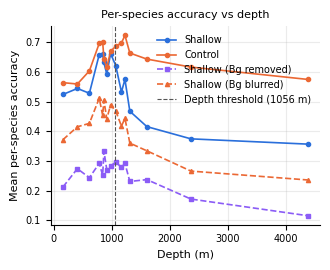

/content/drive/Shareddrives/CV-Project/analysis.py:315: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per = df.groupby([bin_col, "species"])["correct"].mean()
/content/drive/Shareddrives/CV-Project/analysis.py:316: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return per.groupby(bin_col).mean()
/content/drive/Shareddrives/CV-Project/analysis.py:315: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per = df.groupby([bin_col,

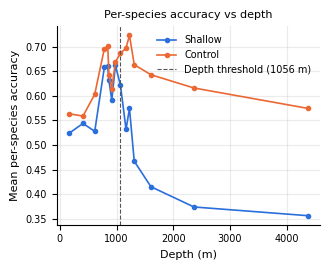

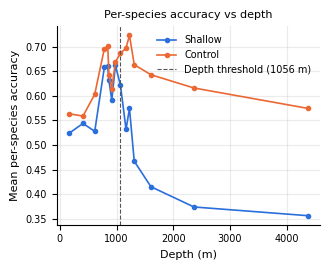

In [30]:
importlib.reload(extensions)
importlib.reload(analysis)


# Shallow model — per-species degradation before and after interventions
ctx_df_grey, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='shallow', mode='grey_bg')
ctx_df_blur, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='shallow', mode='blur_bg')


# Continuous line plot — shallow model
extensions.plot_degradation_before_after(
    ctx_df_grey, df_blur=ctx_df_blur,
    save_path='results/degradation_before_after.png')

# Binned bar charts
extensions.plot_degradation_bar(
    ctx_df_grey, mode_label='background removed',
    save_path='results/degradation_bar_grey.png')

extensions.plot_degradation_bar(
    ctx_df_blur, mode_label='background blurred',
    save_path='results/degradation_bar_blur.png')

# --- Control model (negative control for regression to the mean) ---
print('\n--- Control model ---')
ctrl_df_grey, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='control', mode='grey_bg')
ctrl_df_blur, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='control', mode='blur_bg')

extensions.plot_degradation_before_after(
    ctrl_df_grey, df_blur=ctrl_df_blur,
    save_path='results/degradation_before_after_control.png')

extensions.plot_degradation_bar(
    ctrl_df_grey, mode_label='background removed',
    save_path='results/degradation_bar_grey_control.png')

# Accuracy vs depth

analysis.plot_accuracy_vs_depth(
    predictions, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    int_preds=int_preds, int_modes=['grey_bg', 'blur_bg'],
    save_path='results/accuracy_vs_depth_bgintervention.png')

# Species-weighted accuracy vs depth — every species counts equally

# Filter to qualifying species for fair species-weighted comparison
qual_preds = predictions[predictions['species'].isin(qualifying)]
qual_int = int_preds[int_preds['species'].isin(qualifying)]

analysis.plot_accuracy_vs_depth(
    qual_preds, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    int_preds=qual_int, int_modes=['grey_bg', 'blur_bg'],
    species_weighted=True,
    save_path='results/accuracy_vs_depth_species_weighted.png')

# Report Fig. 2: the same species-weighted curve without the intervention overlays
analysis.plot_accuracy_vs_depth(
    qual_preds, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    species_weighted=True,
    save_path='results/accuracy_vs_depth_per_species.png')


### High-degradation species
The overall Spearman looks for one trend across every species, so background
reliance that drives degradation in only some species gets diluted. Here the top
quartile of degradation (fixed in advance; other cutoffs are a sensitivity check
only) is compared with the rest on CRS and background reliance, and quantile
regression tests whether the upper tail of degradation rises with excess CRS.
A species can only degrade as far as its shallow accuracy, so the test is
repeated on relative degradation (degradation / shallow accuracy), and
`shallow_acc` is shown per group as a check.

In [31]:
importlib.reload(extensions)
hd_df = per_species_df.join(ctx_df_grey['bg_reliance'])
hd_df['relative_degradation'] = hd_df['degradation'] / hd_df['shallow_acc'].where(hd_df['shallow_acc'] > 0)

for deg_col in ['degradation', 'relative_degradation']:
    tbl = extensions.high_degradation_test(hd_df, species=qualifying, deg_col=deg_col)
    tbl.to_csv(os.path.join(config.RESULTS_DIR, f'high_{deg_col}_test.csv'))
    display(tbl.round(3))

# Sensitivity to the cutoff (report, don't pick from)
for q in [0.67, 0.9]:
    t = extensions.high_degradation_test(hd_df, species=qualifying, quantile=q)
    print(t.loc[['shallow_crs_excess', 'bg_reliance'], ['diff', 'p']].round(3))

High degradation: >= 0.302 (35 of 139 species)


,high_mean,rest_mean,diff,p,n_high,n_rest
shallow_crs,0.427,0.419,0.008,0.594,35.0,96.0
shallow_crs_excess,-0.310,-0.324,0.014,0.484,35.0,96.0
shallow_crs_pred_excess,-0.310,-0.324,0.014,0.484,35.0,96.0
bg_reliance,0.626,0.574,0.051,0.559,35.0,96.0
shallow_acc,0.750,0.549,0.201,0.002,35.0,104.0


High relative_degradation: >= 0.575 (33 of 131 species)


,high_mean,rest_mean,diff,p,n_high,n_rest
shallow_crs,0.431,0.418,0.013,0.523,33.0,98.0
shallow_crs_excess,-0.298,-0.327,0.029,0.174,33.0,98.0
shallow_crs_pred_excess,-0.298,-0.327,0.029,0.174,33.0,98.0
bg_reliance,0.607,0.582,0.026,0.310,33.0,98.0
shallow_acc,0.545,0.667,-0.121,0.028,33.0,98.0


High degradation: >= 0.203 (46 of 139 species)
                     diff      p
shallow_crs_excess  0.021  0.248
bg_reliance         0.064  0.536
High degradation: >= 0.520 (14 of 139 species)
                     diff      p
shallow_crs_excess  0.062  0.023
bg_reliance         0.148  0.226


In [32]:
# Tail test: does the upper end of degradation rise with excess CRS, even if the middle doesn't?
import statsmodels.formula.api as smf
qr_df = hd_df.loc[qualifying, ['degradation', 'shallow_crs_excess']].dropna()
for q in [0.5, 0.75, 0.9]:
    fit = smf.quantreg('degradation ~ shallow_crs_excess', qr_df).fit(q=q)
    lo, hi = fit.conf_int().loc['shallow_crs_excess']
    print(f"quantile {q}: slope = {fit.params['shallow_crs_excess']:.3f} "
          f"[{lo:.3f}, {hi:.3f}], p = {fit.pvalues['shallow_crs_excess']:.3g}")

quantile 0.5: slope = -0.113 [-0.540, 0.313], p = 0.599
quantile 0.75: slope = 0.606 [0.036, 1.175], p = 0.0374
quantile 0.9: slope = 0.210 [-0.412, 0.831], p = 0.506


## Sensitivity check: same-species masks
Everything above uses the target annotation alone as the organism, so another
individual of the same species in the crop counts as context. Here CRS is
recomputed (train notebook, last section) with every annotation of the
target's species in the crop counted as organism — the pointing-game
convention (Zhang et al. 2016), and a better match for Grad-CAM, which
highlights every individual of the explained class. Only crops with another
annotated individual of the species (`extra_organisms`) can change.

If the conclusions above hold under both mask definitions, they aren't an
artefact of how neighbouring individuals are labelled.

shallow: 14.8% of 13551 qualifying-species test crops contain another individual of the same species
deep: 13.1% of 10440 qualifying-species test crops contain another individual of the same species
Spearman ρ between the two species CRS rankings: 0.980 (n = 131)


,crs_target,crs_same_species,change
count,131.000,131.000,131.000
mean,0.421,0.410,-0.011
std,0.144,0.145,0.027
min,0.143,0.143,-0.155
25%,0.308,0.298,-0.006
50%,0.408,0.397,0.000
75%,0.523,0.513,0.000
max,0.925,0.925,0.000


,crs_target,crs_same_species,change
species,,,
Bathochordaeus mcnutti,0.401,0.246,-0.155
Marrus claudanielis,0.380,0.243,-0.137
Vesicomya,0.671,0.540,-0.130
Vesicomyidae,0.506,0.397,-0.109
Kephyes ovata,0.440,0.339,-0.101
Marrus orthocanna,0.483,0.408,-0.075
Isosicyonis,0.335,0.280,-0.055
Prayidae,0.456,0.402,-0.054
Tottonophyes enigmatica,0.320,0.270,-0.050


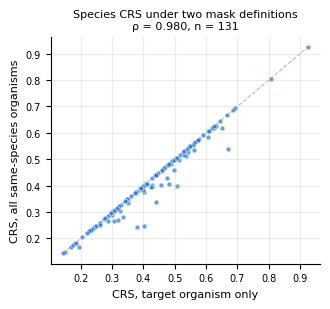

In [33]:
import matplotlib.pyplot as plt

crs_sp = pd.read_csv(os.path.join(config.RESULTS_DIR, 'crs_same_species.csv'), index_col='species')
all_ic_sp = pd.read_csv(os.path.join(config.RESULTS_DIR, 'image_crs_same_species.csv'))
image_crs_sp = {s: all_ic_sp[all_ic_sp['split'] == s].drop(columns='split') for s in ['shallow', 'deep']}

# Same-species species CRS from correct shallow crops only, like the target-only CRS (cell 3)
sp_correct = attribution.species_crs_table(image_crs_sp['shallow'][image_crs_sp['shallow']['correct']],
                                           crs_sp.index.tolist(), prefix='shallow_')
sp_cols = [c for c in sp_correct.columns if c in crs_sp.columns]
crs_sp[sp_cols] = sp_correct[sp_cols]

# How many crops does the mask definition affect?
for s, ic in image_crs_sp.items():
    q = ic[ic['species'].isin(qualifying)]
    print(f"{s}: {q['extra_organisms'].mean():.1%} of {len(q)} qualifying-species test crops "
          f"contain another individual of the same species")

# Per-species CRS under the two definitions
mask_cmp = pd.DataFrame({'crs_target': per_species_df['shallow_crs'].reindex(qualifying),
                         'crs_same_species': crs_sp['shallow_crs'].reindex(qualifying)}).dropna()
mask_cmp['change'] = mask_cmp['crs_same_species'] - mask_cmp['crs_target']
rho_cmp = mask_cmp['crs_target'].corr(mask_cmp['crs_same_species'], method='spearman')
print(f"Spearman ρ between the two species CRS rankings: {rho_cmp:.3f} (n = {len(mask_cmp)})")
display(mask_cmp.describe().round(3))
display(mask_cmp.sort_values('change').head(10).round(3))   # species whose CRS drops most

fig, ax = plt.subplots(figsize=(3.4, 3.2))
lo, hi = mask_cmp[['crs_target', 'crs_same_species']].min().min(), mask_cmp[['crs_target', 'crs_same_species']].max().max()
ax.plot([lo, hi], [lo, hi], color='#bbbbbb', linewidth=0.8, linestyle='--', zorder=0)
ax.scatter(mask_cmp['crs_target'], mask_cmp['crs_same_species'], s=12, color='#2a78d6', alpha=0.7,
           edgecolor='white', linewidth=0.4)
ax.set_xlabel('CRS, target organism only', fontsize=8)
ax.set_ylabel('CRS, all same-species organisms', fontsize=8)
ax.set_title(f'Species CRS under two mask definitions\nρ = {rho_cmp:.3f}, n = {len(mask_cmp)}', fontsize=8, pad=6)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=7)
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig('results/crs_target_vs_same_species.png', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
importlib.reload(extensions)
importlib.reload(analysis)

# Re-run the main CRS tests under both mask definitions, side by side
versions = {
    'target only': (per_species_df, image_crs),
    'same species': (crs_sp.join(per_species_df['degradation']), image_crs_sp),
}
learned = [s for s in qualifying if shallow_acc[s] >= 0.3]

rows = {}
for name, (sp_df, ic) in versions.items():
    print(f"\n=== {name} ===")
    scores = sp_df['shallow_crs'].dropna().to_dict()
    rho, p = analysis.spearman_correlation(scores, degradation, species=qualifying)
    rho_l, p_l = analysis.spearman_correlation(scores, degradation, species=learned)
    _, adj, _ = extensions.crs_mask_size_analysis(sp_df, species=qualifying)
    _, var = extensions.crs_variance_analysis(ic['shallow'][ic['shallow']['correct']], degradation, species=qualifying)
    cw = {s: extensions.crs_correct_vs_incorrect(ic[s], species=qualifying, label=f'{name}, {s}')
          for s in ['shallow', 'deep']}
    row = {'mean species CRS': sp_df['shallow_crs'].reindex(qualifying).mean(),
           'ρ CRS vs degradation': rho, 'p': p,
           'ρ CRS vs degradation (shallow_acc ≥ 0.3)': rho_l, 'p (shallow_acc ≥ 0.3)': p_l,
           'ρ excess CRS vs degradation': adj['excess_crs_vs_degradation'][0],
           'p excess': adj['excess_crs_vs_degradation'][1],
           'partial ρ CRS vs degradation (coverage)': adj['partial_crs_vs_degradation'][0],
           'p partial': adj['partial_crs_vs_degradation'][1],
           'ρ CRS std vs degradation': var['std'][0], 'p std': var['std'][1]}
    for s in cw:
        row[f'within-species CRS diff, wrong − right ({s})'] = cw[s]['median_within_species_diff']
        row[f'p within-species ({s})'] = cw[s]['p_within']
    rows[name] = row

mask_def_comparison = pd.DataFrame(rows)
mask_def_comparison.to_csv(os.path.join(config.RESULTS_DIR, 'crs_mask_definition_comparison.csv'))
display(mask_def_comparison.round(4))


=== target only ===
Spearman over 131 species
Spearman over 111 species
Mask coverage vs CRS: ρ = -0.561, p = 3.09e-12, n = 131
Raw CRS vs degradation: ρ = -0.060, p = 0.498, n = 131
Excess CRS vs degradation: ρ = -0.065, p = 0.462, n = 131
CRS vs degradation, controlling for coverage: partial ρ = -0.021, p = 0.814, n = 131
OLS degradation ~ crs + coverage: crs coef = -0.016 (p = 0.529), coverage coef = 0.001 (p = 0.97)
CRS std vs degradation: rho = 0.191, p = 0.0478, n = 108 species
CRS iqr vs degradation: rho = 0.145, p = 0.135, n = 108 species
CRS mean vs degradation: rho = -0.057, p = 0.555, n = 108 species
[target only, shallow] median CRS correct 0.376 vs incorrect 0.501 (pooled p = 5.56e-101); within 101 species, median diff = 0.098 (p = 4.25e-15); empty maps left out: 0 correct, 32 wrong
[target only, deep] median CRS correct 0.434 vs incorrect 0.594 (pooled p = 2.98e-125); within 100 species, median diff = 0.130 (p = 5.05e-15); empty maps left out: 0 correct, 85 wrong

=== sa

,target only,same species
mean species CRS,0.4211,0.4099
ρ CRS vs degradation,-0.0597,-0.0822
p,0.4983,0.3508
ρ CRS vs degradation (shallow_acc ≥ 0.3),0.0165,-0.0177
p (shallow_acc ≥ 0.3),0.8633,0.8537
ρ excess CRS vs degradation,-0.0649,-0.0603
p excess,0.4617,0.4936
partial ρ CRS vs degradation (coverage),-0.0208,-0.0289
p partial,0.8141,0.7438
ρ CRS std vs degradation,0.1909,0.2056
